In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from tensorflow.keras.datasets import fashion_mnist

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
# Load Fashion MNIST dataset

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

print("Training data shape:", X_train.shape)
print("Training labels shape:", y_train.shape)

print("Testing data shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing data shape: (10000, 28, 28)
Testing labels shape: (10000,)


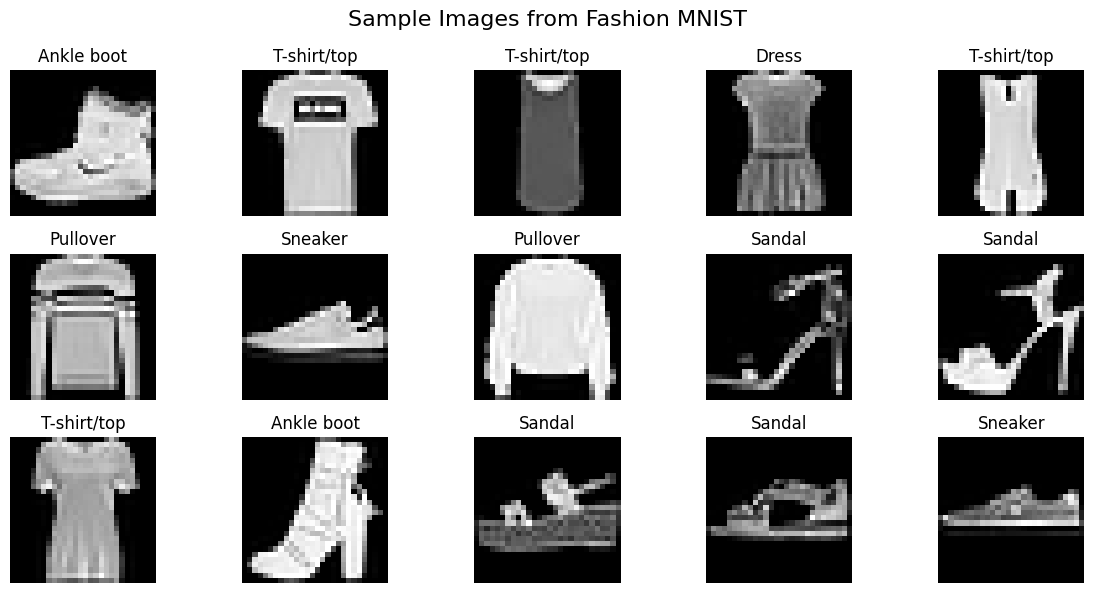

In [3]:
# Define class names

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

# Display sample images

plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.suptitle("Sample Images from Fashion MNIST", fontsize=16)
plt.tight_layout()
plt.show()


In [4]:
# Flatten images into 784-dimensional vectors

X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

# Normalize pixel values to the range [0, 1]

X_train_flat = X_train_flat.astype(np.float32) / 255.0
X_test_flat = X_test_flat.astype(np.float32) / 255.0

# Select stratified subsets

X_train_sub, _, y_train_sub, _ = train_test_split(
    X_train_flat,
    y_train,
    train_size=12000,
    stratify=y_train,
    random_state=42
)

X_test_sub, _, y_test_sub, _ = train_test_split(
    X_test_flat,
    y_test,
    train_size=2000,
    stratify=y_test,
    random_state=42
)

print("Training subset:", X_train_sub.shape)
print("Testing subset:", X_test_sub.shape)


Training subset: (12000, 784)
Testing subset: (2000, 784)


In [5]:
# Define SVM classifiers

models = {
    "Linear SVM": SVC(
        kernel="linear",
        C=1.0
    ),

    "Polynomial SVM": SVC(
        kernel="poly",
        degree=3,
        C=1.0,
        gamma="scale",
        coef0=1.0
    ),

    "RBF SVM": SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    )
}

print("SVM models defined successfully!")


SVM models defined successfully!


In [6]:
# Store trained models and evaluation results

trained_models = {}
results = []

for model_name, svm_model in models.items():

    print("\nTraining:", model_name)

    # Build preprocessing and classification pipeline

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", svm_model)
    ])

    # Measure training time

    start_time = time.time()

    pipeline.fit(X_train_sub, y_train_sub)

    training_time = time.time() - start_time

    # Measure prediction time

    start_time = time.time()

    y_pred = pipeline.predict(X_test_sub)

    prediction_time = time.time() - start_time

    # Calculate evaluation metrics

    accuracy = accuracy_score(y_test_sub, y_pred)

    precision = precision_score(
        y_test_sub,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test_sub,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test_sub,
        y_pred,
        average="macro",
        zero_division=0
    )

    # Save model and results

    trained_models[model_name] = pipeline

    results.append({
        "Model": model_name,
        "Accuracy (%)": accuracy * 100,
        "Precision (%)": precision * 100,
        "Recall (%)": recall * 100,
        "F1-Score (%)": f1 * 100,
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time
    })

    print(f"Accuracy: {accuracy * 100:.2f}%")
    print(f"Precision: {precision * 100:.2f}%")
    print(f"Recall: {recall * 100:.2f}%")
    print(f"F1-Score: {f1 * 100:.2f}%")
    print(f"Training Time: {training_time:.2f} seconds")
    print(f"Prediction Time: {prediction_time:.2f} seconds")

print("\nAll models trained successfully!")



Training: Linear SVM
Accuracy: 80.55%
Precision: 80.48%
Recall: 80.55%
F1-Score: 80.37%
Training Time: 29.49 seconds
Prediction Time: 3.23 seconds

Training: Polynomial SVM
Accuracy: 86.25%
Precision: 86.35%
Recall: 86.25%
F1-Score: 86.26%
Training Time: 13.27 seconds
Prediction Time: 4.79 seconds

Training: RBF SVM
Accuracy: 85.40%
Precision: 85.42%
Recall: 85.40%
F1-Score: 85.35%
Training Time: 14.89 seconds
Prediction Time: 13.78 seconds

All models trained successfully!


In [7]:
# Convert results into a DataFrame

results_df = pd.DataFrame(results)

# Display comparison table

print("SVM Performance Comparison")

display(
    results_df.round(2).sort_values(
        by="Accuracy (%)",
        ascending=False
    ).reset_index(drop=True)
)


SVM Performance Comparison


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%),Training Time (s),Prediction Time (s)
0,Polynomial SVM,86.25,86.35,86.25,86.26,13.27,4.79
1,RBF SVM,85.40,85.42,85.40,85.35,14.89,13.78
2,Linear SVM,80.55,80.48,80.55,80.37,29.49,3.23


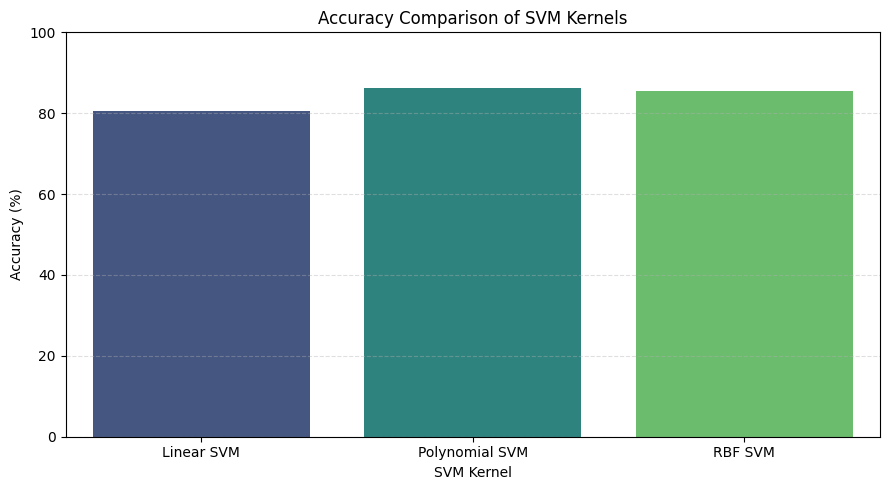

In [8]:
# Plot accuracy comparison

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy (%)",
    hue="Model",
    palette="viridis",
    legend=False
)

plt.title("Accuracy Comparison of SVM Kernels")
plt.xlabel("SVM Kernel")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


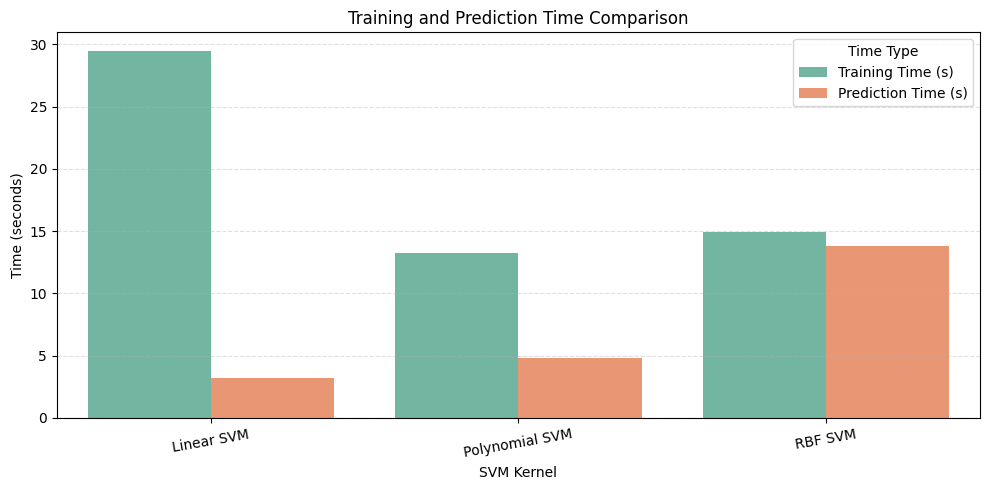

In [9]:
# Plot training and prediction times

time_df = results_df.melt(
    id_vars="Model",
    value_vars=[
        "Training Time (s)",
        "Prediction Time (s)"
    ],
    var_name="Time Type",
    value_name="Time (seconds)"
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=time_df,
    x="Model",
    y="Time (seconds)",
    hue="Time Type",
    palette="Set2"
)

plt.title("Training and Prediction Time Comparison")
plt.xlabel("SVM Kernel")
plt.ylabel("Time (seconds)")
plt.xticks(rotation=10)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


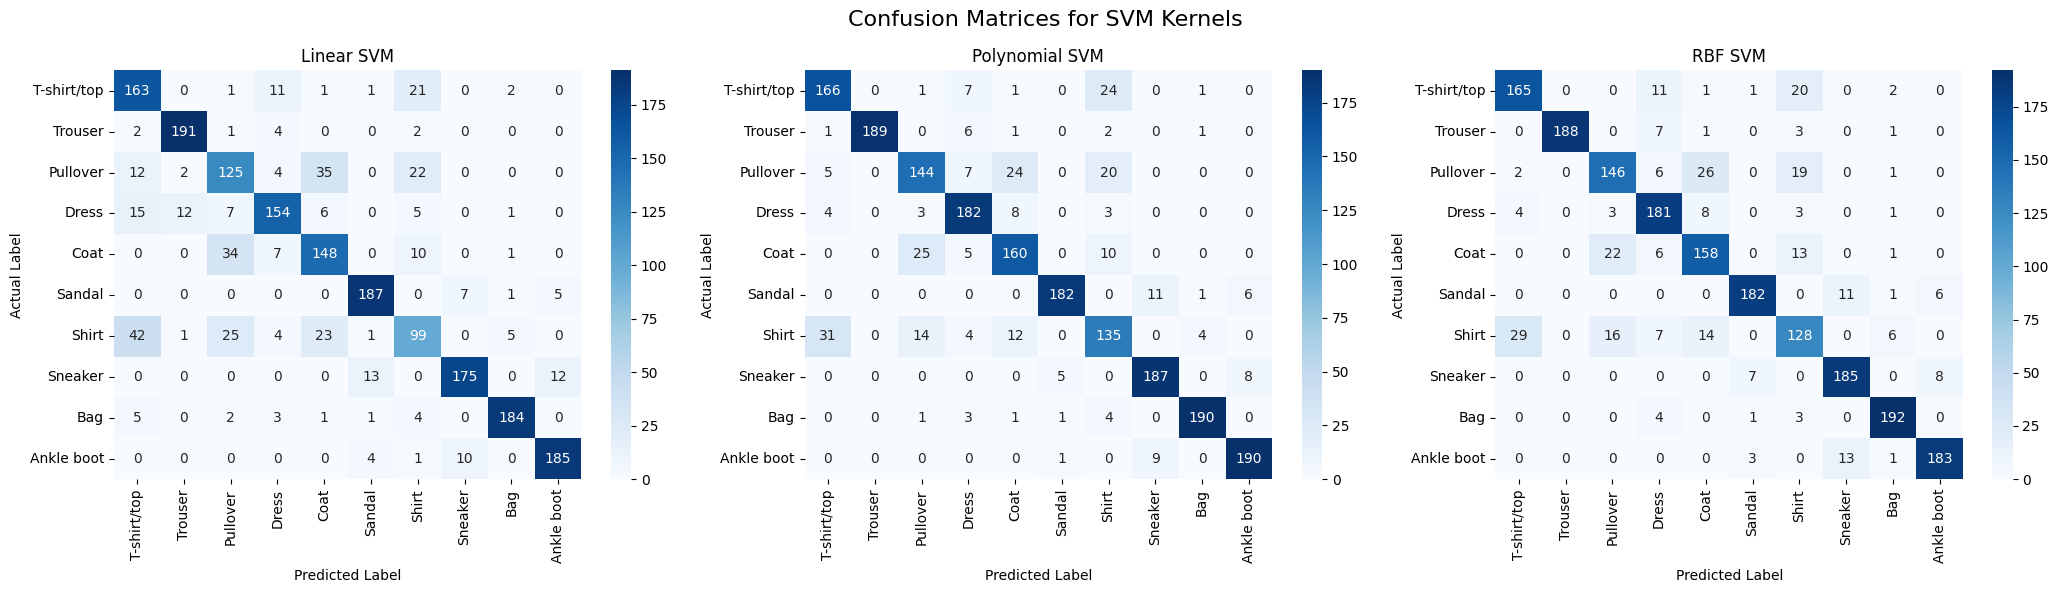

In [10]:
# Generate confusion matrices for all models

fig, axes = plt.subplots(
    1,
    3,
    figsize=(21, 6)
)

for ax, (model_name, pipeline) in zip(
    axes,
    trained_models.items()
):

    y_pred = pipeline.predict(X_test_sub)

    cm = confusion_matrix(
        y_test_sub,
        y_pred,
        labels=np.arange(10)
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle(
    "Confusion Matrices for SVM Kernels",
    fontsize=16
)

plt.tight_layout()
plt.show()


In [11]:
# Print detailed classification reports

for model_name, pipeline in trained_models.items():

    print("\n" + "=" * 70)
    print(model_name)
    print("=" * 70)

    y_pred = pipeline.predict(X_test_sub)

    print(
        classification_report(
            y_test_sub,
            y_pred,
            labels=np.arange(10),
            target_names=class_names,
            zero_division=0
        )
    )



Linear SVM
              precision    recall  f1-score   support

 T-shirt/top       0.68      0.81      0.74       200
     Trouser       0.93      0.95      0.94       200
    Pullover       0.64      0.62      0.63       200
       Dress       0.82      0.77      0.80       200
        Coat       0.69      0.74      0.71       200
      Sandal       0.90      0.94      0.92       200
       Shirt       0.60      0.49      0.54       200
     Sneaker       0.91      0.88      0.89       200
         Bag       0.95      0.92      0.93       200
  Ankle boot       0.92      0.93      0.92       200

    accuracy                           0.81      2000
   macro avg       0.80      0.81      0.80      2000
weighted avg       0.80      0.81      0.80      2000


Polynomial SVM
              precision    recall  f1-score   support

 T-shirt/top       0.80      0.83      0.82       200
     Trouser       1.00      0.94      0.97       200
    Pullover       0.77      0.72      0.74       

In [12]:
# Identify the best model according to test accuracy

best_model_row = results_df.loc[
    results_df["Accuracy (%)"].idxmax()
]

print("Best-performing SVM kernel based on test accuracy:")
print(best_model_row["Model"])

print(
    f"\nTest Accuracy: "
    f"{best_model_row['Accuracy (%)']:.2f}%"
)

print(
    f"Macro Precision: "
    f"{best_model_row['Precision (%)']:.2f}%"
)

print(
    f"Macro Recall: "
    f"{best_model_row['Recall (%)']:.2f}%"
)

print(
    f"Macro F1-Score: "
    f"{best_model_row['F1-Score (%)']:.2f}%"
)

print(
    f"Training Time: "
    f"{best_model_row['Training Time (s)']:.2f} seconds"
)


Best-performing SVM kernel based on test accuracy:
Polynomial SVM

Test Accuracy: 86.25%
Macro Precision: 86.35%
Macro Recall: 86.25%
Macro F1-Score: 86.26%
Training Time: 13.27 seconds


In [ ]:
from sklearn.model_selection import GridSearchCV

# Split the training subset into training and validation sets

X_train_gs, X_val_gs, y_train_gs, y_val_gs = train_test_split(
    X_train_sub,
    y_train_sub,
    test_size=0.2,
    stratify=y_train_sub,
    random_state=42
)

# Define the pipeline

rbf_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf"))
])

# Define hyperparameter combinations

param_grid = {
    "svm__C": [1, 10],
    "svm__gamma": ["scale", 0.001, 0.01]
}

# Perform grid search

grid_search = GridSearchCV(
    estimator=rbf_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train_gs, y_train_gs)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation accuracy:", grid_search.best_score_)

# Evaluate the selected model on the validation set

best_rbf_model = grid_search.best_estimator_

y_val_pred = best_rbf_model.predict(X_val_gs)

print(
    "Validation accuracy:",
    f"{accuracy_score(y_val_gs, y_val_pred) * 100:.2f}%"
)


Fitting 3 folds for each of 6 candidates, totalling 18 fits
